<a href="https://colab.research.google.com/github/chtzortzi-alt/Tzortzi_Facial_Expressions/blob/main/Tzortzi_Imaging_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
!pip install -q kagglehub

Dataset is hosted on Kaggle. The original one was last updated 6 years ago. I prefer an immediate retrieval than working locally and performing a manual upload every time I work on the assignment.

In [42]:
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download("msambare/fer2013")
)

print("Dataset location:", dataset_path)
print("Folder contents:", [p.name for p in dataset_path.iterdir()])

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset location: /kaggle/input/fer2013
Folder contents: ['test', 'train']


Represents the dataset's location and specifies the dataset owner and dataset name. Displays the path to stored location and folder contents confirms the code's availability to access the data.

In [43]:
for item in dataset_path.iterdir():
  print(item.name, "- Directory:", item.is_dir())

test - Directory: True
train - Directory: True


Checks the folders' types. The original dataset contains two subsets of train and test. The training one will be further split to an 80% training and a 20% validation subset using a stratification technique to preserve the original distirbution of the seven facial expression categories. The original test set will remain unchanged.

In [44]:
train_path = dataset_path / "train"
test_path = dataset_path / "test"

train_classes = sorted([
    folder.name
    for folder in train_path.iterdir()
    if folder.is_dir()
])

test_classes = sorted([
    folder.name
    for folder in test_path.iterdir()
    if folder.is_dir()
])

print("Training categories:", train_classes)
print("Testing categories:", test_classes)

Training categories: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Testing categories: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


We check the contents of each separate directory (test, train) wanting to find the same seven facial expression categories. These are sorted alphabetically: anger, disgust, fear, happy, neutral, sad and surprise. This is important so as to ensure consistency during the preprocessing, training and evaluation.

In [45]:
from collections import Counter

extensions = Counter(
    file.suffix.lower()
    for folder in train_path.iterdir()
    if folder.is_dir()
    for file in folder.iterdir()
    if file.is_file()
)

print("Training file extensions:", extensions)

Training file extensions: Counter({'.jpg': 28709})


All images are in .jpg format (training set). Total number of images accounting to 28.709.

In [46]:
from PIL import Image
import numpy as np

sample_path = sorted((train_path / "happy").glob("*.jpg"))[0]

with Image.open(sample_path) as img:
  print("Image format:", img.format)
  print("Image mode:", img.mode)
  print("Image dimensions:", img.size)

  pixels = np.array(img)

print("Array shape:", pixels.shape)
print("Pixel data type:", pixels.dtype)
print("Minimum pixel value:", pixels.min())
print("Maximum pixel value:", pixels.max())

Image format: JPEG
Image mode: L
Image dimensions: (48, 48)
Array shape: (48, 48)
Pixel data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


The instance of an inspected image is grayscale. Therefore, it seems that there won't be a need for conversion. Dimensions appear to be 48x48 and the pixel value range is 0-255. The images will be normalized on a 0-1 scale.

In [47]:
import pandas as pd

data = []

for split, path in [("train", train_path), ("test", test_path)]:
  for folder in sorted(path.iterdir()):
    if folder.is_dir():
      image_count = len([
          file for file in folder.iterdir()
          if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
      ])

      data.append({
          "split": split,
          "expression": folder.name,
          "count": image_count
      })

df = pd.DataFrame(data)

display(df)

,split,expression,count
0,train,angry,3995
1,train,disgust,436
2,train,fear,4097
3,train,happy,7215
4,train,neutral,4965
5,train,sad,4830
6,train,surprise,3171
7,test,angry,958
8,test,disgust,111
9,test,fear,1024


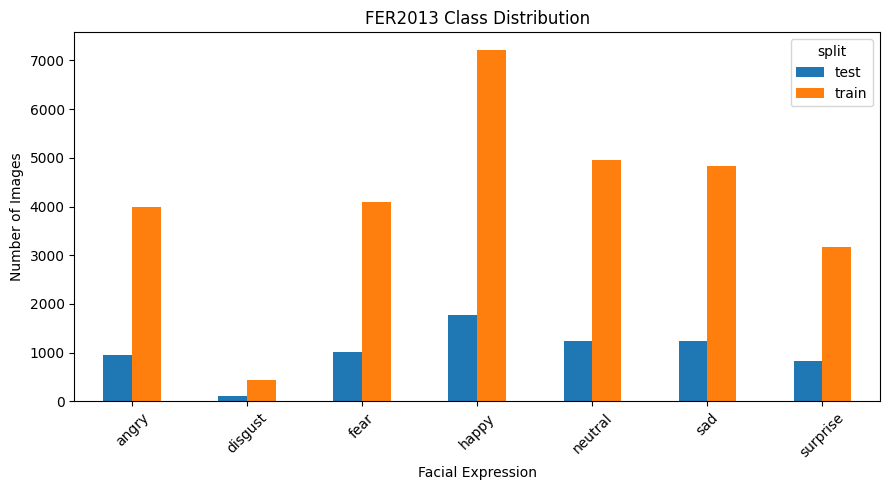

In [48]:
import matplotlib.pyplot as plt

class_counts = df.pivot(
    index = "expression",
    columns = "split",
    values = "count"
)

class_counts.plot(kind = "bar", figsize = (9, 5))

plt.title("FER2013 Class Distribution")
plt.xlabel("Facial Expression")
plt.ylabel("Number of Images")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [49]:
class_percentages = (
    class_counts.div(class_counts.sum(axis = 0), axis = 1) * 100
)

display(class_percentages.round(2))

split,test,train
expression,,
angry,13.35,13.92
disgust,1.55,1.52
fear,14.27,14.27
happy,24.71,25.13
neutral,17.18,17.29
sad,17.37,16.82
surprise,11.58,11.05


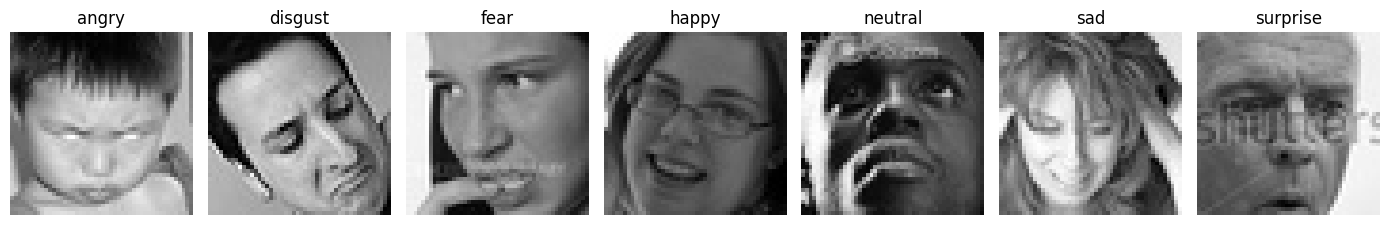

In [50]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 7, figsize = (14, 3))

for i, expression in enumerate(train_classes):
  expression_path = train_path / expression

  image_files = sorted(expression_path.glob("*.jpg"))

  image = Image.open(image_files[0])

  axes[i].imshow(image, cmap = "gray")
  axes[i].set_title(expression)
  axes[i].axis("off")

plt.tight_layout()
plt.show()

In [51]:
from PIL import Image
from collections import Counter

image_properties = Counter()
file_extensions = Counter()
corrupted_files = []

for split, path in [("train", train_path), ("test", test_path)]:
  for expression in train_classes:
    folder = path / expression

    for file in sorted(folder.iterdir()):
      if file.is_file():
        file_extensions[(split, file.suffix.lower())] +=1

        try:
          with Image.open(file) as img:
            img.load

            image_properties[
                (split, img.size, img.mode, img.format)
            ] +=1

        except Exception as e:
              corrupted_files.append((str(file), str(e)))

print("File extensions:", file_extensions)
print("Image properties:", image_properties)
print("Unreadable files:", len(corrupted_files))

if corrupted_files:
  print("Examples:", corrupted_files[:5])


File extensions: Counter({('train', '.jpg'): 28709, ('test', '.jpg'): 7178})

Image properties: Counter({('train', (48, 48), 'L', 'JPEG'): 28709, ('test', (48, 48), 'L', 'JPEG'): 7178})

Unreadable files: 0


Moving on to data preprocessing:

In [52]:
image_records = []

for expression in train_classes:
  expression_folder = train_path / expression

  for image_file in sorted(expression_folder.glob("*.jpg")):
    image_records.append({
        "file_path": str(image_file.relative_to(dataset_path)),
        "expression": expression
    })

images_df = pd.DataFrame(image_records)

display(images_df.head())
print("Total training records:", len(images_df))

,file_path,expression
0,train/angry/Training_10118481.jpg,angry
1,train/angry/Training_10120469.jpg,angry
2,train/angry/Training_10131352.jpg,angry
3,train/angry/Training_10161559.jpg,angry
4,train/angry/Training_1021836.jpg,angry


Total training records: 28709


In [53]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    images_df,
    test_size = 0.20,
    random_state = 42,
    stratify = images_df["expression"]
)

train_df = train_df.reset_index(drop = True)
val_df = val_df.reset_index(drop = True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 22967
Validation images: 5742


In [54]:
train_distribution = train_df["expression"].value_counts(
    normalize = True
) * 100

validation_distribution = val_df["expression"].value_counts(
    normalize = True
) * 100

distribution_comparison = pd.DataFrame({
    "Training (%)": train_distribution,
    "Validation (%)": validation_distribution
})

display(distribution_comparison.round(2))

,Training (%),Validation (%)
expression,,
happy,25.13,25.13
neutral,17.29,17.29
sad,16.82,16.82
fear,14.27,14.28
angry,13.92,13.92
surprise,11.05,11.04
disgust,1.52,1.52


In [55]:
from pathlib import Path

output_dir = Path("/content/splits")
output_dir.mkdir(parents = True, exist_ok = True)

train_df.to_csv(output_dir / "train_split.csv", index = False)
val_df.to_csv(output_dir / "validation_split.csv", index = False)

print("Split files saved to:", output_dir)

Split files saved to: /content/splits


In [56]:
print("Saved files:")

for file in output_dir.iterdir():
  print(file.name, "-", file.stat().st_size, "bytes")

Saved files:
validation_split.csv - 231746 bytes
train_split.csv - 926618 bytes


Training and validation split with manual download to computer and upload to GitHub.
locations on GitHub:
train set: https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/train_split.csv
validation set: https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/validation_split.csv

In [57]:
import pandas as pd

train_url = "https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/train_split.csv"
val_url = "https://raw.githubusercontent.com/chtzortzi-alt/Tzortzi_Facial_Expressions/refs/heads/main/splits/validation_split.csv"

train_df = pd.read_csv(train_url)
val_df = pd.read_csv(val_url)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))

overlap = set(train_df["file_path"]) & set(val_df["file_path"])

print("Overlapping image paths:", len(overlap))

Training records: 22967
Validation records: 5742
Overlapping image paths: 0


Image shape: (48, 48)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


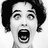

In [58]:
import numpy as np
from PIL import Image

image_path = dataset_path / train_df.iloc[0]["file_path"]

with Image.open(image_path) as img:
  image_array = np.array(img)

print("Image shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

display(Image.open(image_path))

In [59]:
normalized_image = image_array.astype("float32") / 255.0

print("Original data type:", image_array.dtype)
print("Normalized data type:", normalized_image.dtype)

print("Original pixel range:", image_array.min(), image_array.max())
print("Normalized pixel range:", normalized_image.min(), normalized_image.max())

print("Image shape after normalization:", normalized_image.shape)

Original data type: uint8
Normalized data type: float32
Original pixel range: 0 255
Normalized pixel range: 0.0 1.0
Image shape after normalization: (48, 48)


black corresponds to 0, white corresponds to 1, gray to all in-between values

encoding

In [66]:
label_mapping = {
    expression: i
    for i, expression in enumerate(train_classes)
}

print("Label mapping:", label_mapping)

train_df["label"] = train_df["expression"].map(label_mapping).astype("int32")
val_df["label"] = val_df["expression"].map(label_mapping).astype("int32")

print("Training label type:", train_df["label"].dtype)
print("Validation label type:", val_df["label"].dtype)

display(train_df.head())

Label mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}
Training label type: int32
Validation label type: int32


,file_path,expression,label
0,train/fear/Training_21644135.jpg,fear,2
1,train/fear/Training_85697399.jpg,fear,2
2,train/angry/Training_80724752.jpg,angry,0
3,train/happy/Training_8750576.jpg,happy,3
4,train/neutral/Training_16088401.jpg,neutral,4


In [67]:
print("Training labels:")
print(sorted(train_df["label"].unique()))
print("Validation labels:")
print(sorted(val_df["label"].unique()))

print("\nMissing training labels:", train_df["label"].isna().sum())
print("Missing validation labels:", val_df["label"].isna().sum())

Training labels:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]
Validation labels:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]

Missing training labels: 0
Missing validation labels: 0


In [63]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [70]:
def load_image(file_path, label):
  image = tf.io.read_file(file_path)

  image = tf.image.decode_jpeg(
      image, channels = 1
  )

  image = tf.image.convert_image_dtype(
      image, tf.float32
  )

  label = tf.cast(label, tf.int32)

  return image, label

In [71]:
sample_path = str(
    dataset_path / train_df.iloc[0]["file_path"]
)

sample_label = int(train_df.iloc[0]["label"])

image_tensor, label_tensor = load_image(
    sample_path, sample_label
)

print("Tensor shape:", image_tensor.shape)
print("Tensor data type:", image_tensor.dtype)
print("Label data type:", label_tensor.dtype)

print("Minimum pixel value:", float(tf.reduce_min(image_tensor)))
print("Maximum pixel value:", float(tf.reduce_max(image_tensor)))

print("Numerical label:", int(label_tensor.numpy()))
print("Expression:", train_df.iloc[0]["expression"])

Tensor shape: (48, 48, 1)
Tensor data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Numerical label: 2
Expression: fear
